In [ ]:
!pip install -q pystac_client
!pip install -q planetary_computer

In [ ]:
from pystac_client import Client
import planetary_computer

In [ ]:
catalog = Client.open(
    'https://planetarycomputer.microsoft.com/api/stac/v1',
    modifier = planetary_computer.sign_inplace
)

In [ ]:
bbox = [45.885159, 36.861809, 46.210538, 37.132842]

In [ ]:
search = catalog.search(
    collections = ['modis-13A1-061'],
    bbox = bbox,
    datetime = '2001/2025'
)

In [ ]:
items = search.item_collection()

In [ ]:
len(items)

1104

In [ ]:
items[0].assets.keys()

dict_keys(['hdf', '500m_16_days_EVI', '500m_16_days_NDVI', '500m_16_days_VI_Quality', '500m_16_days_MIR_reflectance', '500m_16_days_NIR_reflectance', '500m_16_days_red_reflectance', '500m_16_days_blue_reflectance', '500m_16_days_sun_zenith_angle', '500m_16_days_pixel_reliability', '500m_16_days_view_zenith_angle', '500m_16_days_relative_azimuth_angle', '500m_16_days_composite_day_of_the_year'])

In [ ]:
!pip install -q stackstac
from stackstac import stack

In [ ]:
items_stack = stack(
    items,
    assets = ['500m_16_days_NDVI','500m_16_days_VI_Quality'],
    bounds_latlon = bbox,
    resolution = 500,
    epsg = 3857
)

items_stack = items_stack.assign_coords(time = pd.to_datetime(items_stack.start_datetime.values, utc = True).tz_localize(None))

In [ ]:
import pandas as pd

In [ ]:
ds = (
    items_stack.to_dataset('band')
    .drop_dims('band')
    .reset_coords(drop = True)
    .drop_attrs()
)

In [ ]:
# bit0 = 2 ** 0 = 1, 2 ** 1 = 2, 2 + 1 = 3

In [ ]:
mask = ds['500m_16_days_VI_Quality'].astype(int) & 3
mask = (mask == 0).astype(int)
ndvi = ds['500m_16_days_NDVI'].where(mask).sortby('time')
ndvi = ndvi.sel(time = ndvi.time.dt.year != 2000)

In [ ]:
ndvi_monthly = ndvi.resample(time = 'ME').mean('time')

In [ ]:
from dask.diagnostics import ProgressBar

In [ ]:
import warnings
warnings.filterwarnings('ignore', category = RuntimeWarning)
import logging
logging.getLogger().setLevel(logging.ERROR)

In [ ]:
with ProgressBar():
  ndvi_monthly = ndvi_monthly.compute()

[########################################] | 100% Completed | 431.29 s


In [ ]:
ndvi_interp = ndvi_monthly.interpolate_na(dim = 'time',
                                          method = 'linear',
                                          fill_value = 'extrapolate')

In [ ]:
ndvi_interp

In [ ]:
ndvi_min = ndvi_interp.groupby('time.month').min('time')
ndvi_min = ndvi_min.sel(month = ndvi_interp.time.dt.month)
ndvi_min

In [ ]:
ndvi_max = ndvi_interp.groupby('time.month').max('time')
ndvi_max = ndvi_max.sel(month = ndvi_interp.time.dt.month)
ndvi_max

In [ ]:
vci = ((ndvi_interp - ndvi_min) / (ndvi_max - ndvi_min)) * 100

In [ ]:
vci_annual = vci.resample(time = 'YS').mean('time')

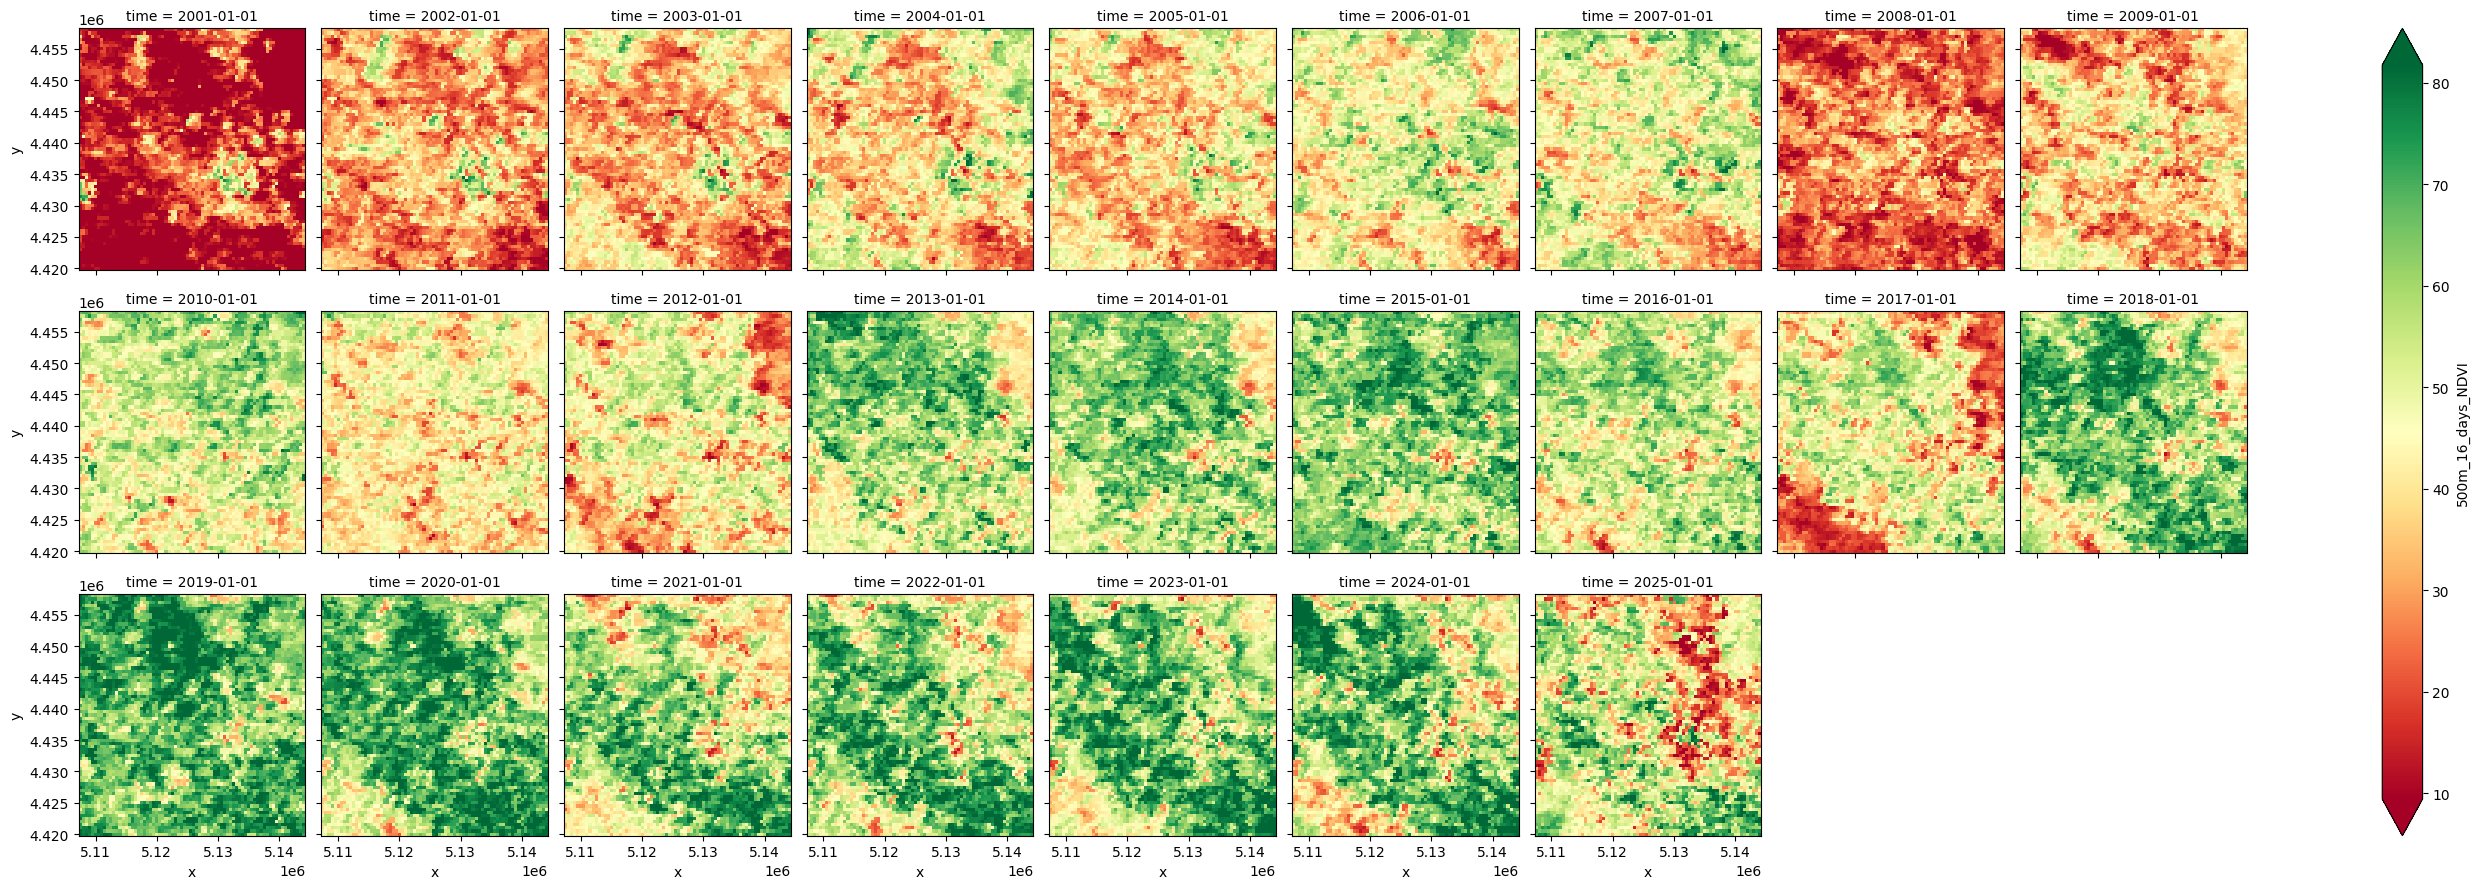

In [ ]:
vci_annual.plot(
    col = 'time',
    col_wrap = 9,
    cmap = 'RdYlGn',
    robust = True
)

In [ ]:
vci_month = vci.mean(dim = ['x','y']).to_dataframe().drop('month',axis = 1)
vci_month

,500m_16_days_NDVI
time,
2001-01-31,21.693954
2001-02-28,15.646572
2001-03-31,31.537626
2001-04-30,26.197153
2001-05-31,15.579031
...,...
2025-08-31,52.057884
2025-09-30,48.819652
2025-10-31,53.695649


<Axes: xlabel='time'>

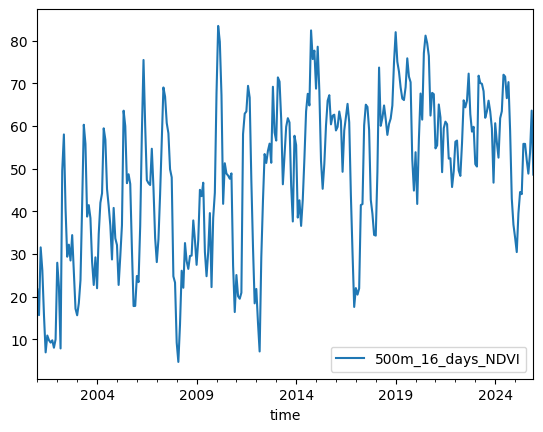

In [ ]:
vci_month.plot()